In [ ]:
from qiskit import __version__
print(__version__)

Ket0 and kat1 creation.

In [96]:
import numpy as np
ket0 = np.array([[1], [0]])
ket1 = np.array([[0], [1]])

print(ket0 / 2 + ket1 / 2)

[[0.5]
 [0.5]]


Creating Matrices

In [4]:
M1 = np.array([[1, 1], [0, 0]])
M2 = np.array([[1, 0], [0, 1]])
M = M1 / 2 + M2 / 2
print(M)

[[1.  0.5]
 [0.  0.5]]


Matrix-vector multiplication

In [6]:
print(M1 @ ket1)
print(M1 @ M2)
print(M @ M)

[[1]
 [0]]
[[1 1]
 [0 0]]
[[1.   0.75]
 [0.   0.25]]


Qiskit Visualization part

In [97]:
from qiskit.visualization import array_to_latex

display(array_to_latex(M1 @ ket1))
display(array_to_latex(M1 @ M2))
display(array_to_latex(M @ M))




<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

Define and display state vectors

from  qiskit.quantum_info import Statevector
from numpy import sqrt

u = Statevector([1 / sqrt(2), 1 / sqrt(2)])
v = Statevector([(1 + 2.0j) / 3, -2 / 3])
w = Statevector([1 /3, 2 /3])

Display of state vectors

In [13]:
display(array_to_latex(u))
display(array_to_latex(v))
display(array_to_latex(w))


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

Display for statevectors

In [16]:
display(u.draw("text"))
display(u.draw("latex"))
print(u.draw("latex_source"))

[0.70710678+0.j,0.70710678+0.j]

<IPython.core.display.Latex object>

\frac{\sqrt{2}}{2} |0\rangle+\frac{\sqrt{2}}{2} |1\rangle


Validation of the quantum state vector which checkes Euclidean norm. 

In [30]:
display(u.is_valid())
display(w.is_valid())
display(v.is_valid())


True

False

True

Simulating measurements using Statevector

In [24]:
display(v.draw("latex"))

<IPython.core.display.Latex object>

Measurements

In [52]:
outcome, state = v.measure()
print(f"Measured: {outcome}\nPost-measurement state:")
display(state.draw("latex"))
display(state.draw("latex_source"))


Measured: 0
Post-measurement state:


<IPython.core.display.Latex object>

'(\\frac{\\sqrt{5}}{5} + \\frac{2 \\sqrt{5} i}{5}) |0\\rangle'

Ploting the Histogram of outcomes

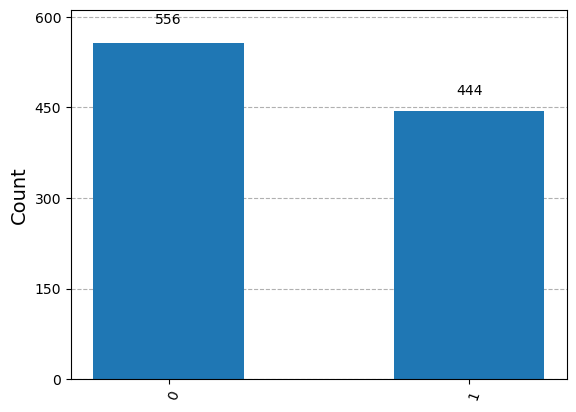

In [53]:
from qiskit.visualization import plot_histogram

statistics = v.sample_counts(1000)
plot_histogram(statistics)

Perform operations with Operator and Statevector

In [93]:
from qiskit.quantum_info import Operator

Y = Operator([[0, -1.0j], [1.0j, 0]])
H = Operator([[1 / sqrt(2), 1 / sqrt(2)],[1 / sqrt(2), -1 / sqrt(2)]])
S = Operator([[1, 0], [0, 1.0j]])
T = Operator([[1, 0], [0, (1 + 1.0j) / (sqrt(2))]])
display(T.draw("latex"))

<IPython.core.display.Latex object>

unitary operation to state vector.

In [78]:
v = Statevector([1, 0])



previously learned review. DISPLAY is playing significant role on commands. 

#Displaying the latex form from array which give matrix
display(array_to_latex(v))
# quantum kat version display
display(v.draw("latex"))
# for text version in sqr parathesis
display(v.draw("text"))
#checking state vector
display(v.is_valid())

A- BE AWARE Multiplication show 2 x 2 matrix although that should be 2 x 1. A and B are the same operations but display differences.

In [80]:
display((H @ v).draw("latex"))

<IPython.core.display.Latex object>

B- Unitary operations_changing Q states

In [81]:
v = v.evolve(H)
display(v.draw("latex"))

<IPython.core.display.Latex object>

In [84]:
v = Statevector([1, 0])
v = v.evolve(H)
v = v.evolve(T)
v = v.evolve(H)
v = v.evolve(S)
v = v.evolve(Y)
display(v.draw("latex"))


<IPython.core.display.Latex object>

sef calculation result display

In [102]:
se = Statevector([[((sqrt(2) * 1.0j) - 1 - 1.0j) / (2 * sqrt(2))],[((1.0j + (sqrt(2) * 1.0j)) - 1) / (2 * sqrt(2))]])
display(se.draw("latex"))

<IPython.core.display.Latex object>

Quantum Circuit, seems similar to v.evolve but compt. background works differently.

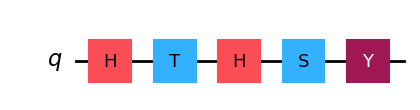

In [108]:
from qiskit import QuantumCircuit

circuit = QuantumCircuit(1)

circuit.h(0)
circuit.t(0)
circuit.h(0)
circuit.s(0)
circuit.y(0)

display(circuit.draw(output="mpl"))

In [105]:
display(Operator.from_circuit(circuit).draw("latex"))

<IPython.core.display.Latex object>

Do not mix Circut use ket0 but below code/ Circuit results matrix 2 x2. BUT below ket0 operation is 2 X 1 matrix. which Unitary matrix applied on ket0 

In [109]:
ket0 = Statevector([1, 0])
v = ket0.evolve(circuit)
display(v.draw("latex"))

<IPython.core.display.Latex object>

In [112]:
ket1 = Statevector([0, 1])
vz = ket1.evolve(circuit)
display(vz.draw("latex"))

<IPython.core.display.Latex object>

Histogram

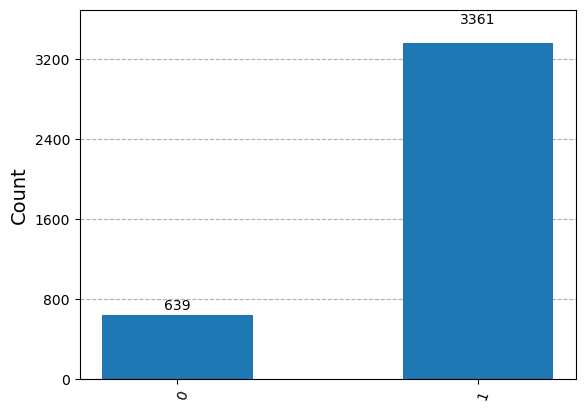

In [113]:
statistics = v.sample_counts(4000)
display(plot_histogram(statistics))